# Tabular Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## DATA LOADING
#### There are two datasets one without infertility and one with it so added both and then merged with respect to Patient file no.

In [2]:
df_inf = pd.read_csv("/kaggle/input/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos/PCOS_infertility.csv")
df_woinf = pd.read_excel("/kaggle/input/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos/PCOS_data_without_infertility.xlsx", sheet_name="Full_new")

In [3]:
df = pd.merge(df_woinf,df_inf, on='Patient File No.', suffixes=('','_y'),how='left')

## DATA PREPROCESSING

In [4]:
df.shape

(541, 50)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 50 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Sl. No                    541 non-null    int64  
 1   Patient File No.          541 non-null    int64  
 2   PCOS (Y/N)                541 non-null    int64  
 3    Age (yrs)                541 non-null    int64  
 4   Weight (Kg)               541 non-null    float64
 5   Height(Cm)                541 non-null    float64
 6   BMI                       541 non-null    float64
 7   Blood Group               541 non-null    int64  
 8   Pulse rate(bpm)           541 non-null    int64  
 9   RR (breaths/min)          541 non-null    int64  
 10  Hb(g/dl)                  541 non-null    float64
 11  Cycle(R/I)                541 non-null    int64  
 12  Cycle length(days)        541 non-null    int64  
 13  Marraige Status (Yrs)     540 non-null    float64
 14  Pregnant(Y

In [6]:
df.describe()

,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Sl. No_y,PCOS (Y/N)_y,I beta-HCG(mIU/mL)_y,II beta-HCG(mIU/mL)_y
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,...,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,0.0,0.0,0.0,0.0
mean,271.000000,271.000000,0.327172,31.430684,59.637153,156.484835,24.311285,13.802218,73.247689,19.243993,...,76.927911,6.129390,6.641405,15.018115,15.451701,8.475915,NaN,NaN,NaN,NaN
std,156.317519,156.317519,0.469615,5.411006,11.028287,6.033545,4.056399,1.840812,4.430285,1.688629,...,5.574112,4.229294,4.436889,3.566839,3.318848,2.165381,NaN,NaN,NaN,NaN
min,1.000000,1.000000,0.000000,20.000000,31.000000,137.000000,12.417882,11.000000,13.000000,16.000000,...,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,136.000000,136.000000,0.000000,28.000000,52.000000,152.000000,21.641274,13.000000,72.000000,18.000000,...,70.000000,3.000000,3.000000,13.000000,13.000000,7.000000,NaN,NaN,NaN,NaN
50%,271.000000,271.000000,0.000000,31.000000,59.000000,156.000000,24.238227,14.000000,72.000000,18.000000,...,80.000000,5.000000,6.000000,15.000000,16.000000,8.500000,NaN,NaN,NaN,NaN
75%,406.000000,406.000000,1.000000,35.000000,65.000000,160.000000,26.634958,15.000000,74.000000,20.000000,...,80.000000,9.000000,10.000000,18.000000,18.000000,9.800000,NaN,NaN,NaN,NaN
max,541.000000,541.000000,1.000000,48.000000,108.000000,180.000000,38.900000,18.000000,82.000000,28.000000,...,100.000000,22.000000,20.000000,24.000000,24.000000,18.000000,NaN,NaN,NaN,NaN


In [7]:
 df.isnull().sum()

Sl. No                        0
Patient File No.              0
PCOS (Y/N)                    0
 Age (yrs)                    0
Weight (Kg)                   0
Height(Cm)                    0
BMI                           0
Blood Group                   0
Pulse rate(bpm)               0
RR (breaths/min)              0
Hb(g/dl)                      0
Cycle(R/I)                    0
Cycle length(days)            0
Marraige Status (Yrs)         1
Pregnant(Y/N)                 0
No. of aborptions             0
  I   beta-HCG(mIU/mL)        0
II    beta-HCG(mIU/mL)        0
FSH(mIU/mL)                   0
LH(mIU/mL)                    0
FSH/LH                        0
Hip(inch)                     0
Waist(inch)                   0
Waist:Hip Ratio               0
TSH (mIU/L)                   0
AMH(ng/mL)                    0
PRL(ng/mL)                    0
Vit D3 (ng/mL)                0
PRG(ng/mL)                    0
RBS(mg/dl)                    0
Weight gain(Y/N)              0
hair gro

### Distribution of PCOS

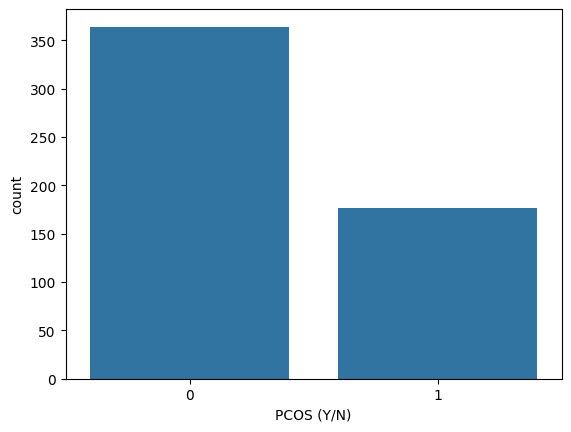

In [8]:
sns.countplot(x='PCOS (Y/N)', data=df)
plt.show()

In [9]:
df['PCOS (Y/N)'].value_counts()

PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

### Majority patients do not have PCOS

In [10]:
df['AMH(ng/mL)'] = pd.to_numeric(
    df['AMH(ng/mL)'],
    errors='coerce'
)

In [11]:
print(df.columns)

Index(['Sl. No', 'Patient File No.', 'PCOS (Y/N)', ' Age (yrs)', 'Weight (Kg)',
       'Height(Cm) ', 'BMI', 'Blood Group', 'Pulse rate(bpm) ',
       'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)',
       'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions',
       '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)',
       'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio',
       'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)',
       'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)',
       'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)',
       'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)',
       'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)',
       'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)',
       'Unnamed: 44', 'Sl. No_y', 'PCOS (Y/N)_y', '  I   beta-HCG(mIU/mL)_y',
       'II    beta-HCG(mIU/mL)_y', 'AMH(ng/mL)_y'],
     

### Remove unnecessary features

In [12]:
cols_to_drop = [
    'Sl. No_y',
    'PCOS (Y/N)_y',
    '  I   beta-HCG(mIU/mL)_y',
    'II    beta-HCG(mIU/mL)_y',
    'AMH(ng/mL)_y',
    'Unnamed: 44'
]

df.drop(columns=cols_to_drop, inplace=True)

### Filled null values

In [13]:
df['Marraige Status (Yrs)'] = df['Marraige Status (Yrs)'].fillna(
    df['Marraige Status (Yrs)'].median()
)

df['Fast food (Y/N)'] = df['Fast food (Y/N)'].fillna(
    df['Fast food (Y/N)'].mode()[0]
)

### Handled object values

In [14]:
df['II    beta-HCG(mIU/mL)'] = pd.to_numeric(
    df['II    beta-HCG(mIU/mL)'],
    errors='coerce'
)

df['AMH(ng/mL)'] = pd.to_numeric(
    df['AMH(ng/mL)'],
    errors='coerce'
)

df['II    beta-HCG(mIU/mL)'] = df['II    beta-HCG(mIU/mL)'].fillna(
    df['II    beta-HCG(mIU/mL)'].median()
)

df['AMH(ng/mL)'] = df['AMH(ng/mL)'].fillna(
    df['AMH(ng/mL)'].median()
)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 44 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Sl. No                  541 non-null    int64  
 1   Patient File No.        541 non-null    int64  
 2   PCOS (Y/N)              541 non-null    int64  
 3    Age (yrs)              541 non-null    int64  
 4   Weight (Kg)             541 non-null    float64
 5   Height(Cm)              541 non-null    float64
 6   BMI                     541 non-null    float64
 7   Blood Group             541 non-null    int64  
 8   Pulse rate(bpm)         541 non-null    int64  
 9   RR (breaths/min)        541 non-null    int64  
 10  Hb(g/dl)                541 non-null    float64
 11  Cycle(R/I)              541 non-null    int64  
 12  Cycle length(days)      541 non-null    int64  
 13  Marraige Status (Yrs)   541 non-null    float64
 14  Pregnant(Y/N)           541 non-null    in

In [16]:
df.isnull().sum()

Sl. No                    0
Patient File No.          0
PCOS (Y/N)                0
 Age (yrs)                0
Weight (Kg)               0
Height(Cm)                0
BMI                       0
Blood Group               0
Pulse rate(bpm)           0
RR (breaths/min)          0
Hb(g/dl)                  0
Cycle(R/I)                0
Cycle length(days)        0
Marraige Status (Yrs)     0
Pregnant(Y/N)             0
No. of aborptions         0
  I   beta-HCG(mIU/mL)    0
II    beta-HCG(mIU/mL)    0
FSH(mIU/mL)               0
LH(mIU/mL)                0
FSH/LH                    0
Hip(inch)                 0
Waist(inch)               0
Waist:Hip Ratio           0
TSH (mIU/L)               0
AMH(ng/mL)                0
PRL(ng/mL)                0
Vit D3 (ng/mL)            0
PRG(ng/mL)                0
RBS(mg/dl)                0
Weight gain(Y/N)          0
hair growth(Y/N)          0
Skin darkening (Y/N)      0
Hair loss(Y/N)            0
Pimples(Y/N)              0
Fast food (Y/N)     

In [17]:
print(df[['II    beta-HCG(mIU/mL)', 'AMH(ng/mL)']].dtypes)

II    beta-HCG(mIU/mL)    float64
AMH(ng/mL)                float64
dtype: object


In [18]:
df['PCOS (Y/N)'].value_counts()

PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

In [19]:
df['PCOS (Y/N)'].value_counts(normalize=True)*100

PCOS (Y/N)
0    67.28281
1    32.71719
Name: proportion, dtype: float64

In [20]:
df = df.drop(
    columns=['Sl. No', 'Patient File No.']
)

## CORREALATION ANALYSIS

In [21]:
corr_target = df.corr(numeric_only=True)['PCOS (Y/N)']

corr_target.sort_values(
    ascending=False
)

PCOS (Y/N)                1.000000
Follicle No. (R)          0.648327
Follicle No. (L)          0.603346
Skin darkening (Y/N)      0.475733
hair growth(Y/N)          0.464667
Weight gain(Y/N)          0.441047
Cycle(R/I)                0.401644
Fast food (Y/N)           0.376183
Pimples(Y/N)              0.286077
AMH(ng/mL)                0.264141
Weight (Kg)               0.211938
BMI                       0.199534
Hair loss(Y/N)            0.172879
Waist(inch)               0.164598
Hip(inch)                 0.162297
Avg. F size (L) (mm)      0.132992
Endometrium (mm)          0.106648
Avg. F size (R) (mm)      0.097690
Pulse rate(bpm)           0.091821
Hb(g/dl)                  0.087170
Vit D3 (ng/mL)            0.085494
Height(Cm)                0.068254
Reg.Exercise(Y/N)         0.065337
LH(mIU/mL)                0.063879
RBS(mg/dl)                0.048922
BP _Diastolic (mmHg)      0.038032
RR (breaths/min)          0.036928
Blood Group               0.036433
II    beta-HCG(mIU/m

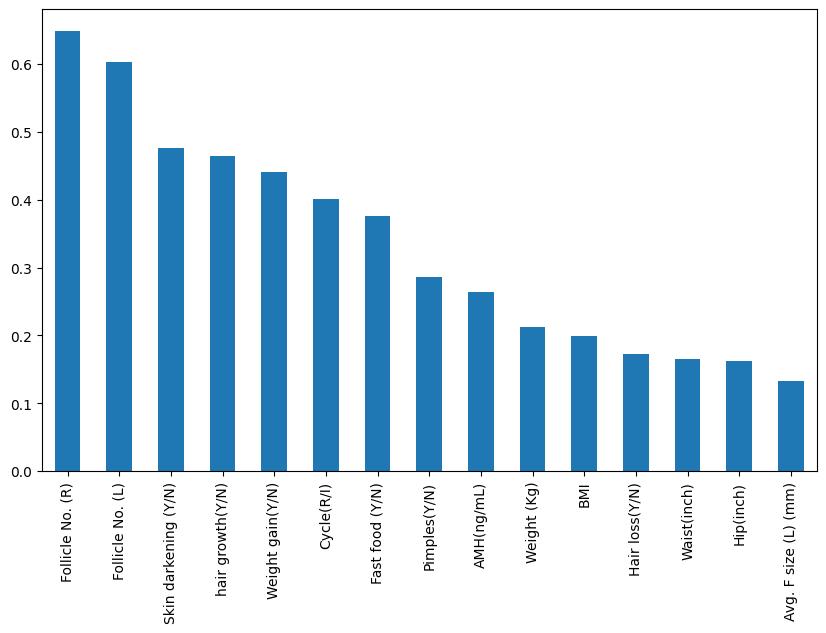

In [22]:
corr_target = df.corr(numeric_only=True)['PCOS (Y/N)']

top_corr = corr_target.drop('PCOS (Y/N)').sort_values(ascending=False)[:15]

plt.figure(figsize=(10,6))
top_corr.plot(kind='bar')
plt.xticks(rotation=90)
plt.show()

In [23]:
X = df.drop('PCOS (Y/N)', axis=1)
y = df['PCOS (Y/N)']

## Train-Test Split

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### FEATURE SELECTION

#### Mutual Information

In [25]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)

mi_df = pd.DataFrame({
    "Feature": X_train.columns,
    "MI Score": mi_scores
})

mi_df = mi_df.sort_values(
    by="MI Score",
    ascending=False
)

display(mi_df)

,Feature,MI Score
36,Follicle No. (L),0.230539
37,Follicle No. (R),0.212063
27,Weight gain(Y/N),0.103957
28,hair growth(Y/N),0.103282
9,Cycle length(days),0.095560
29,Skin darkening (Y/N),0.088677
22,AMH(ng/mL),0.081805
18,Hip(inch),0.062510
32,Fast food (Y/N),0.055437
8,Cycle(R/I),0.053822


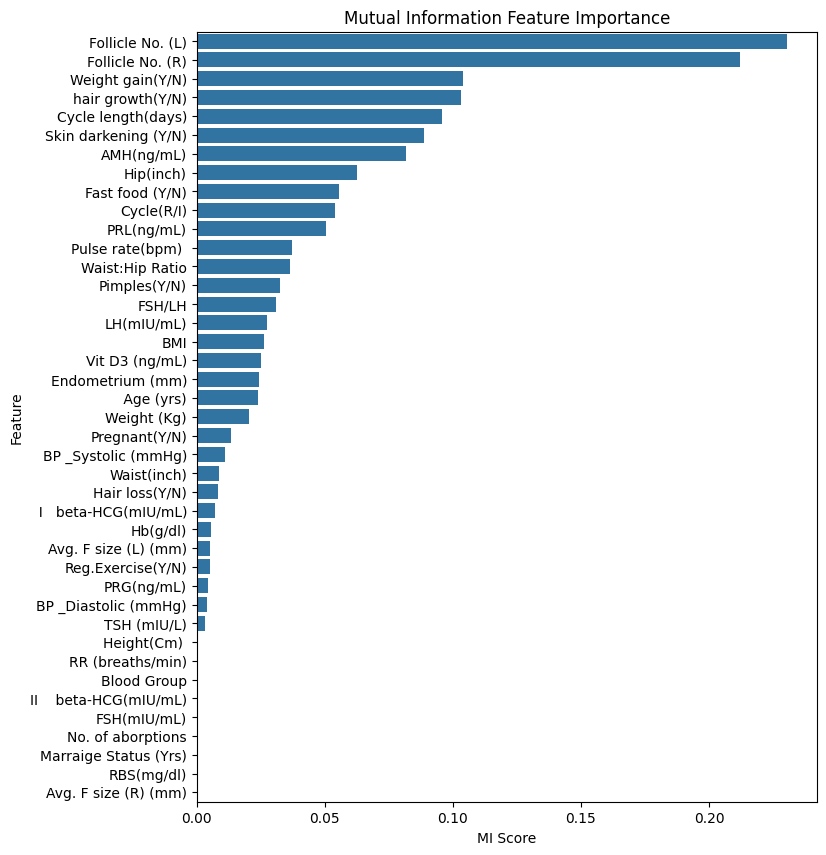

In [26]:
plt.figure(figsize=(8,10))

sns.barplot(
    data=mi_df,
    x="MI Score",
    y="Feature"
)

plt.title("Mutual Information Feature Importance")
plt.show()

In [27]:
selected_features = mi_df[
    mi_df["MI Score"] > 0.02
]["Feature"].tolist()
X_train_fs = X_train[selected_features]
X_test_fs = X_test[selected_features]

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

In [29]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_fs)
X_test_scaled = scaler.transform(X_test_fs)

In [30]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(kernel='rbf', probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss')
}

In [31]:
results = []

for name, model in models.items():

    # Models requiring scaled data
    if name in ["Logistic Regression", "KNN", "Naive Bayes", "SVM"]:
        Xtr = X_train_scaled
        Xte = X_test_scaled
    else:
        Xtr = X_train_fs
        Xte = X_test_fs

    model.fit(Xtr, y_train)

    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
results_df.sort_values("Accuracy", ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,SVM,0.935780,0.939394,0.861111,0.898551,0.955860
0,Logistic Regression,0.926606,0.888889,0.888889,0.888889,0.964992
6,Gradient Boosting,0.926606,0.911765,0.861111,0.885714,0.957002
5,Random Forest,0.926606,0.937500,0.833333,0.882353,0.949011
7,XGBoost,0.926606,0.966667,0.805556,0.878788,0.963090
1,KNN,0.889908,0.875000,0.777778,0.823529,0.939878
2,Naive Bayes,0.889908,0.875000,0.777778,0.823529,0.958524
4,Decision Tree,0.834862,0.750000,0.750000,0.750000,0.813356


### CROSS - VALIDATION

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Cross Validation Strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [33]:
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

In [34]:
cv_results = []

for name, model in models.items():

    if name in ["Logistic Regression", "KNN", "Naive Bayes", "SVM"]:
        X = X_train_scaled
    else:
        X = X_train_fs

    scores = cross_validate(
        model,
        X,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)
cv_df.sort_values("Accuracy", ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.895964,0.852679,0.830049,0.839764,0.946447
6,Gradient Boosting,0.893718,0.869391,0.808867,0.835077,0.942619
3,SVM,0.893611,0.874012,0.794581,0.830233,0.951783
5,Random Forest,0.891312,0.893913,0.766256,0.822326,0.956767
1,KNN,0.888987,0.934266,0.716502,0.808787,0.929353
7,XGBoost,0.877493,0.830423,0.801724,0.812444,0.941488
2,Naive Bayes,0.856669,0.846409,0.709360,0.765330,0.935596
4,Decision Tree,0.787249,0.677581,0.680788,0.677923,0.759769


### SOMTE


In [35]:
from imblearn.over_sampling import SMOTE

In [36]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_fs, y_train)

In [37]:
print("Before SMOTE",y_train.value_counts())
print("\nAfter SMOTE",y_train_smote.value_counts())

Before SMOTE PCOS (Y/N)
0    291
1    141
Name: count, dtype: int64

After SMOTE PCOS (Y/N)
0    291
1    291
Name: count, dtype: int64


In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_smote_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test_fs)

In [39]:
results_smote = []

for name, model in models.items():

    # Models requiring scaled data
    if name in ["Logistic Regression", "KNN", "Naive Bayes", "SVM"]:
        Xtr = X_train_smote_scaled
        Xte = X_test_scaled
    else:
        Xtr = X_train_smote
        Xte = X_test_fs

    # Train the model
    model.fit(Xtr, y_train_smote)

    # Predictions
    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1]

    # Store results
    results_smote.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Create DataFrame
results_smote_df = pd.DataFrame(results_smote)

# Display results
results_smote_df.sort_values("Accuracy", ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,SVM,0.908257,0.842105,0.888889,0.864865,0.948630
2,Naive Bayes,0.908257,0.861111,0.861111,0.861111,0.952816
0,Logistic Regression,0.889908,0.800000,0.888889,0.842105,0.931887
7,XGBoost,0.889908,0.852941,0.805556,0.828571,0.945586
6,Gradient Boosting,0.889908,0.815789,0.861111,0.837838,0.937215
5,Random Forest,0.880734,0.810811,0.833333,0.821918,0.926560
1,KNN,0.871560,0.761905,0.888889,0.820513,0.924467
4,Decision Tree,0.761468,0.613636,0.750000,0.675000,0.758562


## Selected Model

In [40]:
svm_model = models["SVM"]

## FEATURE IMPORTANCE

In [41]:
from sklearn.inspection import permutation_importance

In [42]:
result = permutation_importance(
    svm_model,
    X_test_scaled,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='f1'
)

In [43]:
feature_importance = pd.DataFrame({
    'Feature': X_train_fs.columns,
    'Importance': result.importances_mean
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                 Feature  Importance
1       Follicle No. (R)    0.114061
0       Follicle No. (L)    0.068696
3       hair growth(Y/N)    0.043092
15            LH(mIU/mL)    0.027650
19             Age (yrs)    0.025072
2       Weight gain(Y/N)    0.022261
9             Cycle(R/I)    0.013571
12       Waist:Hip Ratio    0.011898
8        Fast food (Y/N)    0.011291
5   Skin darkening (Y/N)    0.008581
11      Pulse rate(bpm)     0.004489
4     Cycle length(days)    0.002498
6             AMH(ng/mL)    0.001910
17        Vit D3 (ng/mL)    0.000000
13          Pimples(Y/N)    0.000000
14                FSH/LH    0.000000
18      Endometrium (mm)   -0.001281
20           Weight (Kg)   -0.004739
10            PRL(ng/mL)   -0.005464
16                   BMI   -0.006586
7              Hip(inch)   -0.009542


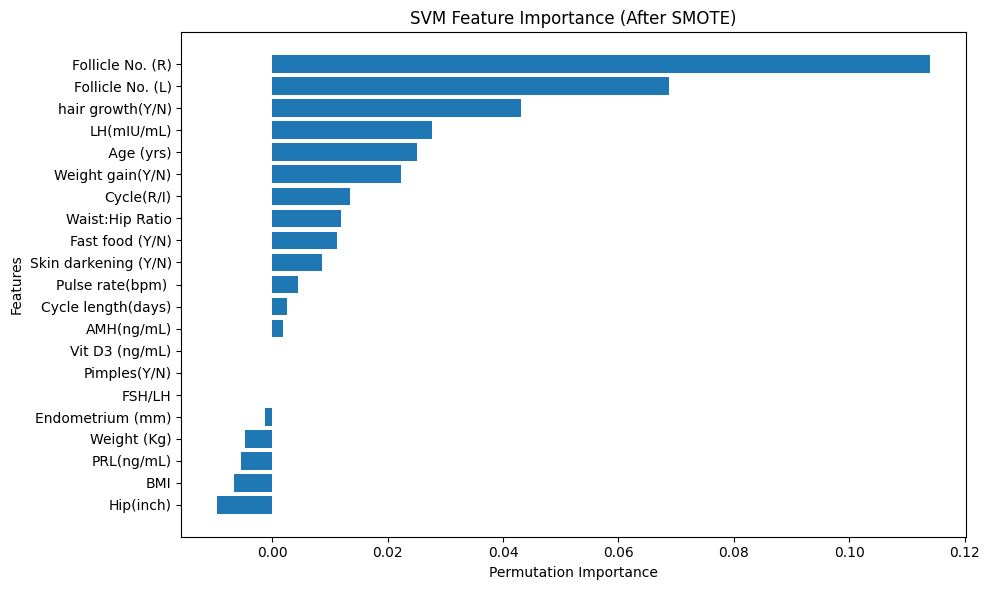

In [44]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Permutation Importance')
plt.ylabel('Features')
plt.title('SVM Feature Importance (After SMOTE)')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## SHAP

In [45]:
import shap
print("SHAP Version:", shap.__version__)

SHAP Version: 0.51.0


In [46]:
# Select background samples from training data
background = shap.sample(
    X_train_smote_scaled,
    50,
    random_state=42
)

# Initialize SHAP explainer
explainer = shap.KernelExplainer(
    svm_model.predict_proba,
    background
)

In [47]:
X_test_sample = X_test_scaled[:50]

shap_values = explainer.shap_values(
    X_test_sample,
    nsamples=100
)

  0%|          | 0/50 [00:00<?, ?it/s]

In [48]:
print(type(shap_values))
print("SHAP shape:", getattr(shap_values, "shape", None))

<class 'numpy.ndarray'>
SHAP shape: (50, 21, 2)


(50, 21)


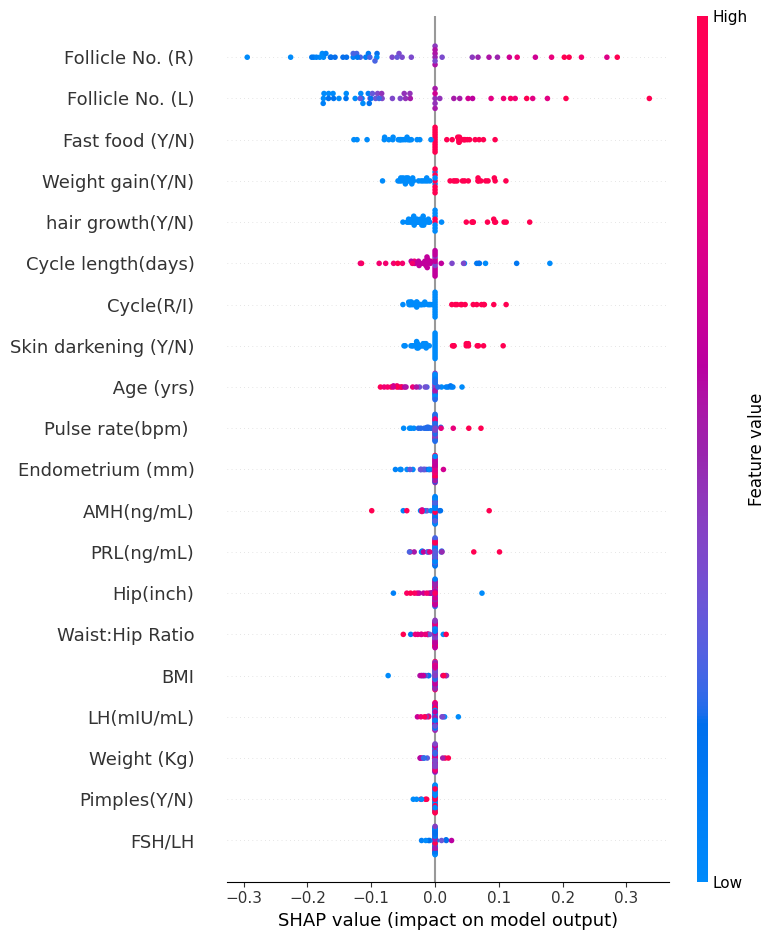

In [49]:
shap_values_positive = shap_values[:, :, 1]
print(shap_values_positive.shape)
shap.summary_plot(
    shap_values_positive,
    X_test_sample,
    feature_names=X_train_fs.columns
)

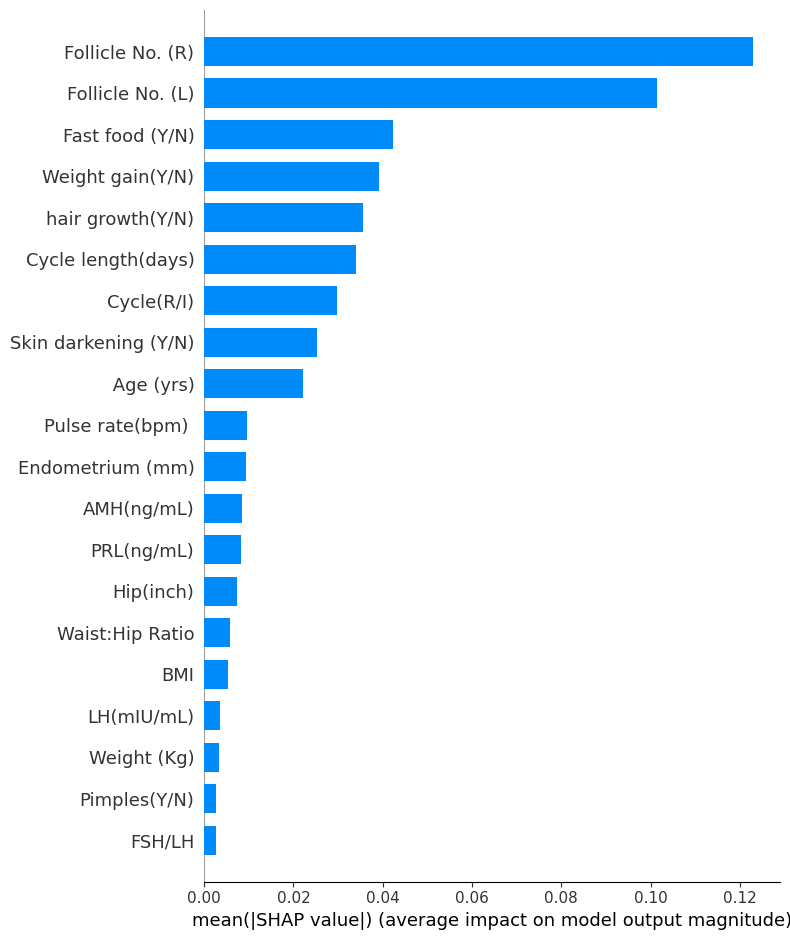

In [50]:
shap.summary_plot(
    shap_values_positive,
    X_test_sample,
    feature_names=X_train_fs.columns,
    plot_type="bar"
)

## ROC CURVE

In [51]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

In [52]:
# Get predicted probabilities for positive class
y_prob = svm_model.predict_proba(X_test_scaled)[:, 1]

# Calculate FPR and TPR
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
roc_auc = auc(fpr, tpr)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.9486301369863014


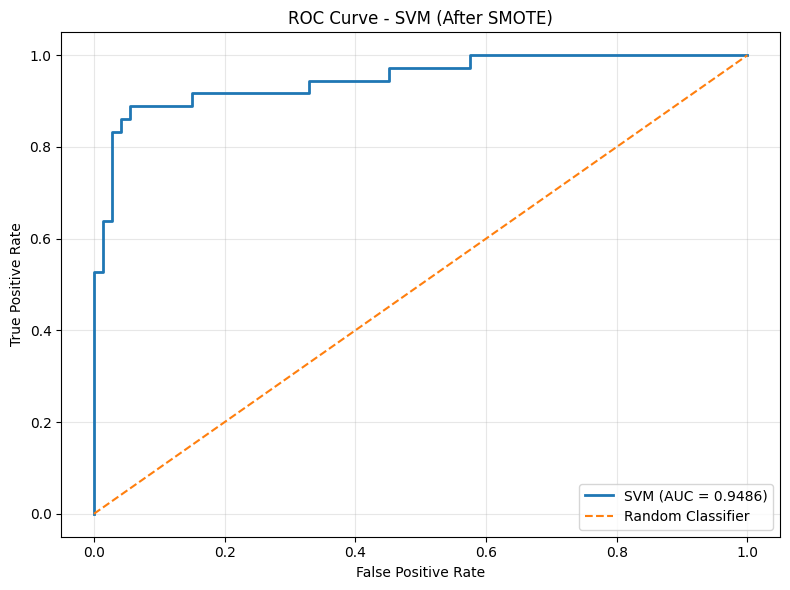

In [53]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f'SVM (AUC = {roc_auc:.4f})',
    linewidth=2
)

plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - SVM (After SMOTE)')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Complete explanation is done after the ROC Curve of ANN Model

## COFUSION MATRIX

In [54]:
from sklearn.metrics import confusion_matrix, classification_report

# Predict class labels
y_pred = svm_model.predict(X_test_scaled)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[67  6]
 [ 4 32]]


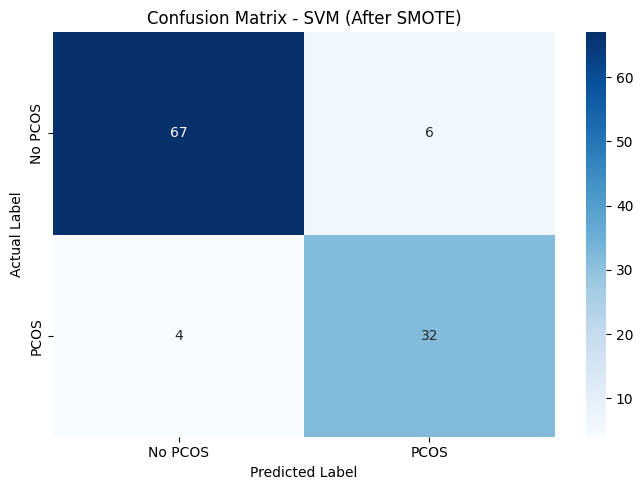

In [55]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No PCOS', 'PCOS'],
    yticklabels=['No PCOS', 'PCOS']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - SVM (After SMOTE)')

plt.tight_layout()
plt.show()

In [56]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['No PCOS', 'PCOS']
))

              precision    recall  f1-score   support

     No PCOS       0.94      0.92      0.93        73
        PCOS       0.84      0.89      0.86        36

    accuracy                           0.91       109
   macro avg       0.89      0.90      0.90       109
weighted avg       0.91      0.91      0.91       109



## ADDITION OF ANN MODEL

In [57]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

ann = Sequential([
    
    Dense(64, activation='relu',
          input_shape=(X_train_scaled.shape[1],)),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dropout(0.3),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])

2026-11-13 17:23:22.168988: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1794590602.467352      97 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1794590602.560280      97 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1794590603.277860      97 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794590603.277933      97 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794590603.277938      97 computation_placer.cc:177] computation placer alr

In [58]:
ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [59]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [60]:
history = ann.fit(
    X_train_smote_scaled,
    y_train_smote,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6215 - loss: 0.6743 - val_accuracy: 0.2735 - val_loss: 0.7853
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7527 - loss: 0.5621 - val_accuracy: 0.5299 - val_loss: 0.6899
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8108 - loss: 0.4522 - val_accuracy: 0.6154 - val_loss: 0.6273
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8344 - loss: 0.3747 - val_accuracy: 0.6667 - val_loss: 0.5825
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8710 - loss: 0.3273 - val_accuracy: 0.7179 - val_loss: 0.5055
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8753 - loss: 0.3016 - val_accuracy: 0.7607 - val_loss: 0.4722
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8903 - loss: 0.2758 - val_accuracy: 0.7692 - val_loss: 0.4874
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8946 - loss: 0.2520 - val_accuracy: 0.7863 - 

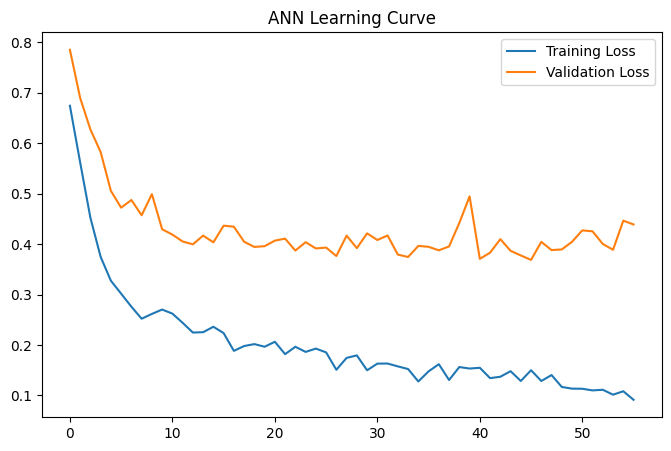

In [61]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.legend()
plt.title("ANN Learning Curve")
plt.show()

In [62]:
loss, accuracy = ann.evaluate(
    X_test_scaled,
    y_test
)
print("Accuracy:", accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8991 - loss: 0.2415 
Accuracy: 0.8990825414657593


In [63]:
y_prob = ann.predict(X_test_scaled)
y_pred = (y_prob > 0.5).astype(int)

annAcc = accuracy_score(y_test, y_pred)
annPrec = precision_score(y_test, y_pred)
annRec = recall_score(y_test, y_pred)
annF1 = f1_score(y_test, y_pred)
annROC = roc_auc_score(y_test, y_prob)

print("Accuracy :", annAcc)
print("Precision:", annPrec)
print("Recall   :", annRec)
print("F1 Score :", annF1)
print("ROC-AUC  :", annROC)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Accuracy : 0.8990825688073395
Precision: 0.8378378378378378
Recall   : 0.8611111111111112
F1 Score : 0.8493150684931506
ROC-AUC  : 0.9615677321156773


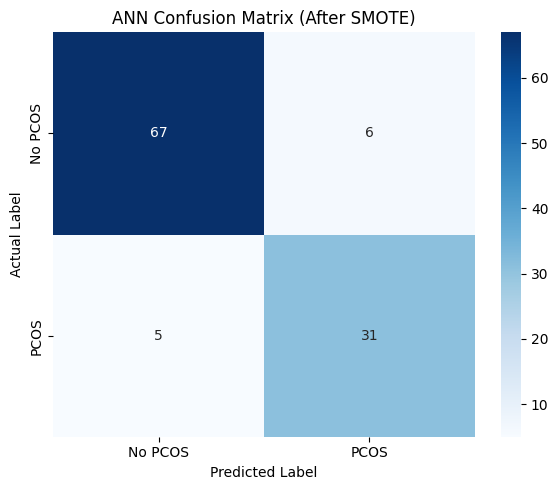

In [64]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No PCOS', 'PCOS'],
    yticklabels=['No PCOS', 'PCOS']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('ANN Confusion Matrix (After SMOTE)')

plt.tight_layout()
plt.show()

In [65]:
ann_results = pd.DataFrame([{
    "Model": "ANN",
    "Accuracy": annAcc,
    "Precision": annPrec,
    "Recall": annRec,
    "F1 Score": annF1,
    "ROC-AUC": annROC
}])

combined_results = pd.concat(
    [results_smote_df, ann_results],
    ignore_index=True
)

combined_results = combined_results.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print(combined_results.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0          Naive Bayes    0.9083     0.8611  0.8611    0.8611   0.9528
1                  SVM    0.9083     0.8421  0.8889    0.8649   0.9486
2                  ANN    0.8991     0.8378  0.8611    0.8493   0.9616
3  Logistic Regression    0.8899     0.8000  0.8889    0.8421   0.9319
4    Gradient Boosting    0.8899     0.8158  0.8611    0.8378   0.9372
5              XGBoost    0.8899     0.8529  0.8056    0.8286   0.9456
6        Random Forest    0.8807     0.8108  0.8333    0.8219   0.9266
7                  KNN    0.8716     0.7619  0.8889    0.8205   0.9245
8        Decision Tree    0.7615     0.6136  0.7500    0.6750   0.7586


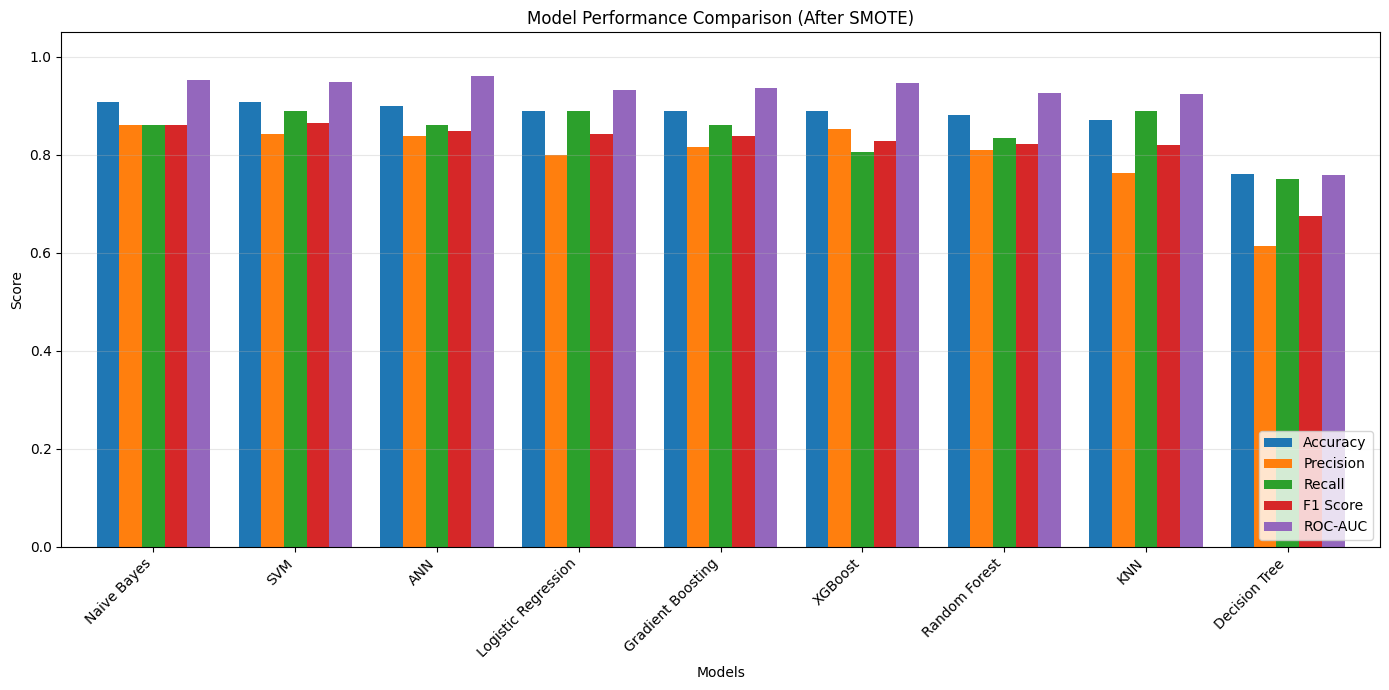

In [66]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

combined_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Model Performance Comparison (After SMOTE)")
plt.ylabel("Score")
plt.xlabel("Models")
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [67]:
for metric in metrics:
    best_idx = combined_results[metric].idxmax()

    print(
        f"Best {metric}: "
        f"{combined_results.loc[best_idx, 'Model']} "
        f"({combined_results.loc[best_idx, metric]:.4f})"
    )

Best Accuracy: Naive Bayes (0.9083)
Best Precision: Naive Bayes (0.8611)
Best Recall: SVM (0.8889)
Best F1 Score: SVM (0.8649)
Best ROC-AUC: ANN (0.9616)


## Saving best Model (SVM)

In [68]:
import joblib

# Get the trained SVM model
svm_model = models["SVM"]

# Create a bundle containing everything needed for prediction
pcos_model_bundle = {
    "model": svm_model,
    "scaler": scaler,
    "feature_names": X_train_fs.columns.tolist()
}

# Save the bundle
joblib.dump(pcos_model_bundle, "pcos_svm_model.pkl")

print("PCOS SVM model saved successfully!")

PCOS SVM model saved successfully!


In [69]:
loaded_bundle = joblib.load("pcos_svm_model.pkl")

loaded_model = loaded_bundle["model"]
loaded_scaler = loaded_bundle["scaler"]
feature_names = loaded_bundle["feature_names"]

print("Model:", loaded_model)
print("Number of features:", len(feature_names))
print("Features:", feature_names)

Model: SVC(probability=True, random_state=42)
Number of features: 21
Features: ['Follicle No. (L)', 'Follicle No. (R)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Cycle length(days)', 'Skin darkening (Y/N)', 'AMH(ng/mL)', 'Hip(inch)', 'Fast food (Y/N)', 'Cycle(R/I)', 'PRL(ng/mL)', 'Pulse rate(bpm) ', 'Waist:Hip Ratio', 'Pimples(Y/N)', 'FSH/LH', 'LH(mIU/mL)', 'BMI', 'Vit D3 (ng/mL)', 'Endometrium (mm)', ' Age (yrs)', 'Weight (Kg)']
